# Turbofan Engine Remaining Useful Life (NASA C-MAPSS)

Exploratory analysis and remaining-useful-life (RUL) prediction for the NASA C-MAPSS turbofan engine degradation data (FD001 and FD002). Covers careful loading, sensor screening, smoothing, operating-regime clustering, baseline correction and a residual-based comparison of Linear Regression and Random Forest models.

Download the data from NASA's Prognostics Data Repository and place the `CMAPSSData` folder inside `data/`.

## Setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)

## 1. Load the training data

In [2]:
import pandas as pd

PATH = "data/CMAPSSData/train_FD001.txt"
q1_df = None

cols = ["unit", "cycle", "os1", "os2", "os3"]
for i in range(1, 22):
    cols.append("s" + str(i))

q1_df = pd.read_csv(PATH, sep=r"\s+", header=None, names=cols)

q1_shape = q1_df.shape
q1_n_engines = q1_df["unit"].nunique()

q1_n_sensors = 0
for col in q1_df.columns:
    if col.startswith("s"):
        q1_n_sensors = q1_n_sensors + 1

lifetimes = q1_df.groupby("unit")["cycle"].max()
q1_life_min = lifetimes.min()
q1_life_med = lifetimes.median()
q1_life_max = lifetimes.max()

trap_df = pd.read_csv(PATH, sep=" ", header=None)
empty_cols = []
for col in trap_df.columns:
    if trap_df[col].isna().all():
        empty_cols.append(col)
print(f"with sep=' ': shape {trap_df.shape}, fully empty columns: {empty_cols}")

print("shape:", q1_shape, "| engines:", q1_n_engines, "| sensors:", q1_n_sensors)
print("lifetime min/median/max:", q1_life_min, q1_life_med, q1_life_max)

with sep=' ': shape (20631, 28), fully empty columns: [26, 27]
shape: (20631, 26) | engines: 100 | sensors: 21
lifetime min/median/max: 128 199.0 362


**Interpretation**

The file loads into a DataFrame of shape (20631, 26), covering 100 engines with 21 sensors. Engine lifetimes vary quite a lot, with a minimum of 128 cycles, a median of 199 cycles and a maximum of 362 cycles, so the longest-running engine lasts almost three times as long as the shortest.

When cross-checking against readme.txt, there is an inconsistency. The readme states the file has 26 columns, but its column list runs from "sensor measurement 1" all the way to "sensor measurement 26". With 5 columns already used by the unit number, cycle and three operational settings, 26 sensors would mean 31 columns in total. The loaded file only has 26 columns, which leaves room for just 21 sensors, so the last line of the readme should read "sensor measurement 21". This shows that the documentation cannot be taken at face value and has to be checked against the actual data. It also matters because the file has no header row, so the column names are assigned by us, and following the readme blindly would label the columns wrongly.

The one loading trap is that every row ends with two trailing spaces. If the file is read with `sep=" "`, pandas treats each trailing space as another separator and creates two extra columns (26 and 27) that are completely empty, giving a shape of (20631, 28) instead of (20631, 26). The line that avoids this is:

`q1_df = pd.read_csv(PATH, sep=r"\s+", header=None, names=cols)`

Using `sep=r"\s+"` treats any run of whitespace as a single separator so the trailing spaces are ignored, and `header=None` stops pandas from using the first row of data as column names.

## 2. Find constant sensor columns

In [3]:
import pandas as pd

check_cols = ["os1", "os2", "os3"]
for i in range(1, 22):
    check_cols.append("s" + str(i))

rows = []
for col in check_cols:
    rows.append({
        "column": col,
        "variance": q1_df[col].var(),
        "n_unique": q1_df[col].nunique(),
        "min": q1_df[col].min(),
        "max": q1_df[col].max()
    })
q2_table = pd.DataFrame(rows)

q2_dead_cols = []
q2_dead_values = {}
for index, row in q2_table.iterrows():
    if row["n_unique"] <= 2:
        q2_dead_cols.append(row["column"])
        q2_dead_values[row["column"]] = q1_df[row["column"]].mode()[0]

fd2_check = pd.read_csv("data/CMAPSSData/train_FD002.txt", sep=r"\s+", header=None, names=q1_df.columns)
fd2_rows = []
for col in q2_dead_cols:
    fd2_rows.append({
        "column": col,
        "FD001_n_unique": q1_df[col].nunique(),
        "FD002_n_unique": fd2_check[col].nunique(),
        "FD002_min": fd2_check[col].min(),
        "FD002_max": fd2_check[col].max()
    })
print(pd.DataFrame(fd2_rows).to_string(index=False))
print()

print(q2_table)
print("dead:", q2_dead_cols)
print("values:", q2_dead_values)

column  FD001_n_unique  FD002_n_unique  FD002_min  FD002_max
   os3               1               2      60.00     100.00
    s1               1               6     445.00     518.67
    s5               1               6       3.91      14.62
    s6               2              14       5.71      21.61
   s10               1               9       0.93       1.30
   s16               1               2       0.02       0.03
   s18               1               6    1915.00    2388.00
   s19               1               2      84.93     100.00

   column      variance  n_unique        min        max
0     os1  4.784340e-06       158    -0.0087     0.0087
1     os2  8.588541e-08        13    -0.0006     0.0006
2     os3  0.000000e+00         1   100.0000   100.0000
3      s1  0.000000e+00         1   518.6700   518.6700
4      s2  2.500533e-01       310   641.2100   644.5300
5      s3  3.759099e+01      3012  1571.0400  1616.9100
6      s4  8.101089e+01      4051  1382.2500  1441.4900
7 

**Interpretation**

I treated a column as effectively constant if it takes at most 2 distinct values across all 20,631 FD001 rows. This flags 8 columns: os3 (always 100.0), s1 (518.67), s5 (14.62), s10 (1.30), s16 (0.03), s18 (2388), s19 (100.0), and s6, which only flips between 21.60 and 21.61, so its variance of about 0.000002 is just rounding flicker. os1 and os2 are not on the list because they have 158 and 13 distinct values, but their ranges are tiny (plus or minus 0.0087 and 0.0006), so in practice they are small jitter around one single setting.

Dropping these columns is not automatically safe for FD002. The FD002 check shows that every one of them changes there: os3 takes 2 values (60 and 100), s1 ranges from 445.00 to 518.67, s5 from 3.91 to 14.62, s18 from 1915 to 2388, and s6 has 14 distinct values. They are only flat in FD001 because FD001 runs at a single operating condition (sea level), so fan inlet temperature and pressure and the demanded fan speeds never change. In FD002 these columns move with the operating condition, so they carry information about which flight setting a row was recorded under, and that is needed later to separate condition effects from wear. They may still turn out to be useless for detecting wear, but that has to be checked on FD002 itself rather than copying the FD001 list across.

## 3. Sensor degradation over an engine's life

engine 1 lifetime: 192 cycles
engine 1 mean of first 10 cycles: 1400.84
engine 1 10-cycle mean ending at cycle 50: 1401.57
engine 1 10-cycle mean ending at cycle 100: 1405.41
engine 1 10-cycle mean ending at cycle 150: 1409.89
engine 1 10-cycle mean ending at cycle 175: 1418.73
engine 1 10-cycle mean ending at cycle 192: 1425.92
 from_cycle  to_cycle  from_value  to_value  change
        131       132     1413.25   1405.76   -7.49
        133       134     1410.11   1402.67   -7.44
        142       143     1413.42   1404.21   -9.21
        152       153     1420.83   1414.56   -6.27
        156       157     1421.23   1412.47   -8.76
        164       165     1416.76   1408.09   -8.67
        166       167     1422.37   1414.72   -7.65
        179       180     1429.45   1417.14  -12.31
        182       183     1426.62   1419.03   -7.59
        184       185     1432.52   1424.40   -8.12


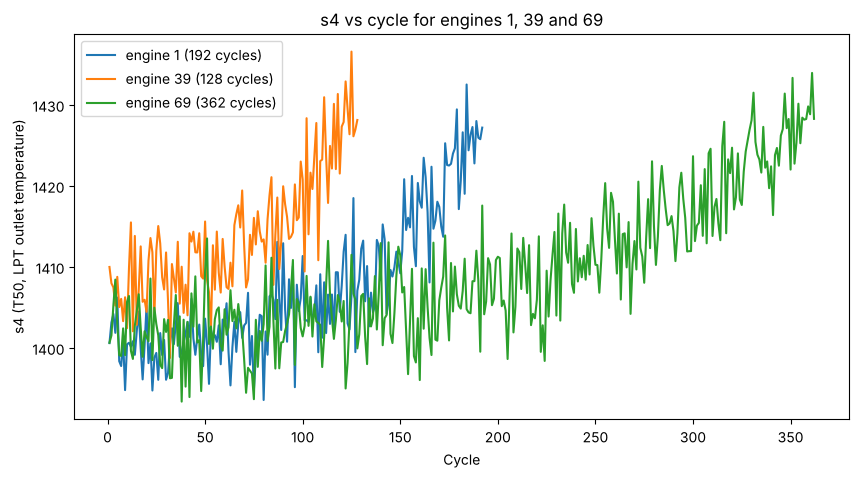

In [4]:
import matplotlib.pyplot as plt

q3_sensor = None

# q1_df was loaded in Q1 (FD001 train). We reuse it here.
q3_sensor = "s4"
q3_units = [1, 39, 69]

engine_1 = q1_df[q1_df["unit"] == 1]
smooth_1 = engine_1[q3_sensor].rolling(10).mean()
print(f"engine 1 lifetime: {engine_1['cycle'].max()} cycles")
print(f"engine 1 mean of first 10 cycles: {engine_1[q3_sensor].head(10).mean():.2f}")
for c in [50, 100, 150, 175, 192]:
    print(f"engine 1 10-cycle mean ending at cycle {c}: {smooth_1[engine_1['cycle'] == c].iloc[0]:.2f}")

big_drops = []
values = engine_1[q3_sensor].tolist()
cycles = engine_1["cycle"].tolist()
for i in range(1, len(values)):
    change = values[i] - values[i - 1]
    if cycles[i] > 130 and change < -5:
        big_drops.append([cycles[i - 1], cycles[i], values[i - 1], values[i], round(change, 2)])
print(pd.DataFrame(big_drops, columns=["from_cycle", "to_cycle", "from_value", "to_value", "change"]).to_string(index=False))

plt.figure(figsize=(10, 5))
for u in q3_units:
    engine = q1_df[q1_df["unit"] == u]
    plt.plot(engine["cycle"], engine[q3_sensor], label=f"engine {u} ({engine['cycle'].max()} cycles)")
plt.xlabel("Cycle")
plt.ylabel(f"{q3_sensor} (T50, LPT outlet temperature)")
plt.title(f"{q3_sensor} vs cycle for engines 1, 39 and 69")
plt.legend()
plt.show()

**Interpretation**

**Interpretation** (claim / which engine + cycles).Provide your answer in this cell:
I picked s4 (T50, total temperature at the LPT outlet), as an exhaust temperature should rise as the engine wears and has to work harder. The three engines are 39 (128 cycles, the shortest life), 1 (192 cycles) and 69 (362 cycles, the longest life). Engine 1's 10-cycle mean starts at 1400.84 and is still only 1401.57 by cycle 50, so the first quarter of its life is basically flat. It then creeps up slowly to 1405.41 by cycle 100 and 1409.89 by cycle 150, before speeding up sharply to 1418.73 at cycle 175 and 1425.92 at failure on cycle 192. Around 16 of the total 25-degree rise happens in the last 42 cycles, so wear builds slowly and then accelerates towards the end.

The plot clearly does not climb in a straight line. The clearest "wrong way" move is engine 1 between cycles 179 and 180, where s4 falls from 1429.45 to 1417.14 (a drop of 12.31) even though the engine is only about 12 cycles from failure. Similar drops appear at cycles 131 to 134 and 184 to 185 (1432.52 to 1424.40). Engine 69 also flattens out and slightly dips between roughly cycles 200 and 230 before climbing again.

A rule like "s4 crosses a fixed value X, so the engine fails next cycle" would misfire for three reasons. First, a single reading jumps around by several degrees from cycle to cycle, which is a big share of the 25-degree wear rise, so an engine can cross X on a noisy spike and drop back below it the next cycle, as engine 1 does at cycle 184. Second, engines start at different levels, and engine 39 starts visibly higher than engine 1 in the plot, so a single X would fire too early on high-baseline engines and too late on low-baseline ones. Third, crossing a value says nothing about how close failure is: engine 69 first goes above 1420 at cycle 255 but keeps running until cycle 362, more than 100 cycles later.

## 4. Smoothing with a rolling mean

window 10 = 7.8% of the shortest life (128) and 5.0% of the median life (199.0)
window 50 = 39.1% of the shortest life and 25.1% of the median life
engine 1: mean of last 5 raw readings = 1425.94, final window-10 value = 1425.92, final window-50 value = 1418.58
engine 39: mean of last 5 raw readings = 1428.84, final window-10 value = 1428.34, final window-50 value = 1420.71
engine 69: mean of last 5 raw readings = 1429.83, final window-10 value = 1428.66, final window-50 value = 1424.40


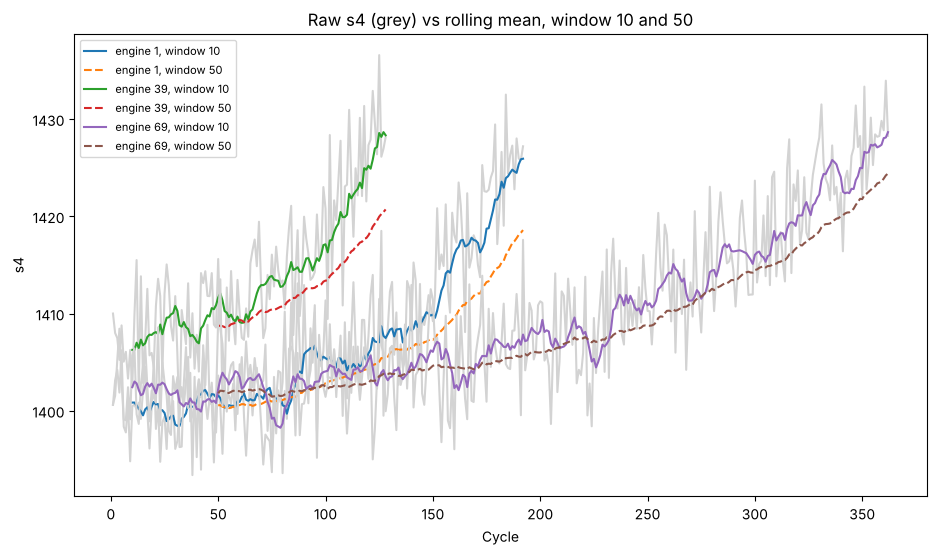

window=10  std raw=5.667  std smoothed=0.599


In [5]:
import matplotlib.pyplot as plt

# Reuses q1_df (Q1, FD001 train) and q3_sensor (the noisy degradation sensor from Q3).
q4_window = 10
big_window = 50
q4_units = [1, 39, 69]

print(f"window {q4_window} = {q4_window / q1_life_min * 100:.1f}% of the shortest life ({q1_life_min}) and {q4_window / q1_life_med * 100:.1f}% of the median life ({q1_life_med})")
print(f"window {big_window} = {big_window / q1_life_min * 100:.1f}% of the shortest life and {big_window / q1_life_med * 100:.1f}% of the median life")

raw_changes = []
smooth_changes = []
plt.figure(figsize=(11, 6))
for u in q4_units:
    engine = q1_df[q1_df["unit"] == u]
    smooth = engine[q3_sensor].rolling(q4_window).mean()
    big_smooth = engine[q3_sensor].rolling(big_window).mean()
    raw_changes.extend(engine[q3_sensor].diff().dropna().tolist())
    smooth_changes.extend(smooth.diff().dropna().tolist())
    plt.plot(engine["cycle"], engine[q3_sensor], color="lightgrey")
    plt.plot(engine["cycle"], smooth, label=f"engine {u}, window {q4_window}")
    plt.plot(engine["cycle"], big_smooth, linestyle="--", label=f"engine {u}, window {big_window}")
    last_raw = engine[q3_sensor].tail(5).mean()
    print(f"engine {u}: mean of last 5 raw readings = {last_raw:.2f}, final window-{q4_window} value = {smooth.iloc[-1]:.2f}, final window-{big_window} value = {big_smooth.iloc[-1]:.2f}")

q4_std_raw = pd.Series(raw_changes).std()
q4_std_smooth = pd.Series(smooth_changes).std()

plt.xlabel("Cycle")
plt.ylabel(q3_sensor)
plt.title(f"Raw {q3_sensor} (grey) vs rolling mean, window {q4_window} and {big_window}")
plt.legend(fontsize=8)
plt.show()
print(f"window={q4_window}  std raw={q4_std_raw:.3f}  std smoothed={q4_std_smooth:.3f}")

**Interpretation**

I chose a trailing rolling mean with a window of 10 cycles. From Q1, the shortest engine lasts 128 cycles and the median engine 199 cycles, so a 10-cycle window is only 7.8% of the shortest life and 5.0% of the median life. This means even the shortest engine still has more than 12 windows' worth of data, and the fast end-of-life rise, which mostly happens in the last 25 to 40 cycles, still spans several windows rather than being swallowed by one. At the same time, averaging 10 readings is enough to remove most of the noise: the standard deviation of the cycle-to-cycle change falls from 5.667 for the raw readings to 0.599 after smoothing, which is roughly 9 times smaller. I used a trailing window (past readings only) because at prediction time future readings are not available, although this adds a lag of about half a window.

Smoothing makes the shape of degradation much easier to see. Each engine shows a flat early phase, a "knee" where it starts to climb (around cycle 90 to 100 for engine 1 and around cycle 200 for engine 69), and then a steep rise to failure. It also shows that engine 39 sits at a higher level than the other two from the start, which is hard to spot in the raw grey lines.

A window that is too large hides exactly the part that matters most. With a 50-cycle window, which is 39.1% of the shortest life, the smoothed line lags well behind the real values at the end. Engine 1's last 5 raw readings average 1425.94, but the 50-cycle mean only reaches 1418.58, about 7 degrees lower, and engine 39 shows the same gap (1428.84 raw against 1420.71). So the fast end-of-life rise gets flattened into a gentle slope, making the engine look healthier than it is right before failure. A large window also irons out Q3's wiggles completely, including any genuine short-term changes, and produces nothing at all for the first 50 cycles, which is almost 40% of engine 39's life.

## 5. Physics prediction vs data ranking of sensors

In [6]:
q5_physics = ["s3", "s7", "s11", "s4"]

q5_df = q1_df.copy()
q5_df["RUL"] = q5_df.groupby("unit")["cycle"].transform("max") - q5_df["cycle"]

symbols = ["T2", "T24", "T30", "T50", "P2", "P15", "P30", "Nf", "Nc", "epr", "Ps30",
           "phi", "NRf", "NRc", "BPR", "farB", "htBleed", "Nf_dmd", "PCNfR_dmd", "W31", "W32"]

corr_rows = []
for i in range(1, 22):
    sensor = "s" + str(i)
    if sensor in q2_dead_cols and q5_df[sensor].nunique() == 1:
        corr = float("nan")
    else:
        corr = q5_df[sensor].corr(q5_df["RUL"])
    corr_rows.append({
        "sensor": sensor,
        "symbol": symbols[i - 1],
        "corr_with_RUL": round(corr, 3),
        "abs_corr": round(abs(corr), 3),
        "physics_pick": sensor in q5_physics,
        "q2_dead": sensor in q2_dead_cols
    })

q5_rank = pd.DataFrame(corr_rows)
q5_rank = q5_rank.sort_values("abs_corr", ascending=False)
q5_rank = q5_rank.reset_index(drop=True)
q5_rank["rank"] = q5_rank.index + 1
print(q5_rank.to_string(index=False))

print()
for sensor in q5_physics:
    sensor_rank = q5_rank[q5_rank["sensor"] == sensor]["rank"].iloc[0]
    print(f"physics pick {sensor}: rank {sensor_rank} of 21")

print()
for col in q2_dead_cols:
    if col.startswith("s"):
        print(f"{col} ({symbols[int(col[1:]) - 1]}): unique values in FD001 = {q1_df[col].nunique()}, value = {q2_dead_values[col]}")

sensor    symbol  corr_with_RUL  abs_corr  physics_pick  q2_dead  rank
   s11      Ps30         -0.696     0.696          True    False     1
    s4       T50         -0.679     0.679          True    False     2
   s12       phi          0.672     0.672         False    False     3
    s7       P30          0.657     0.657          True    False     4
   s15       BPR         -0.643     0.643         False    False     5
   s21       W32          0.636     0.636         False    False     6
   s20       W31          0.629     0.629         False    False     7
    s2       T24         -0.606     0.606         False    False     8
   s17   htBleed         -0.606     0.606         False    False     9
    s3       T30         -0.585     0.585          True    False    10
    s8        Nf         -0.564     0.564         False    False    11
   s13       NRf         -0.563     0.563         False    False    12
    s9        Nc         -0.390     0.390         False    False    13
   s14

**Interpretation**

**Did physics predict the data-driven ranking?** Provide your answer in this cell.
**(a) Physics prediction.** I predicted 4 sensors at or just after the HPC:
- **s3 (T30, temperature at HPC outlet):** a worn compressor is less efficient, so it heats the air more to reach the same pressure, and the outlet temperature should rise.
- **s7 (P30, total pressure at HPC outlet):** a worn compressor cannot build as much pressure, so P30 should fall.
- **s11 (Ps30, static pressure at HPC outlet):** measured at the same station as P30, so it should shift with it.
- **s4 (T50, temperature at LPT outlet):** this is downstream. To keep the same thrust with a weaker compressor, more fuel is burnt and the turbines work harder, so the exhaust temperature should rise.

**(b) Data ranking.**
1. **Rank:** ranked by |corr| with RUL, the top 10 are s11 (-0.696), s4 (-0.679), s12 (0.672), s7 (0.657), s15 (-0.643), s21 (0.636), s20 (0.629), s2 (-0.606), s17 (-0.606) and s3 (-0.585).
2. **Compare with (a):** physics did well. s11 ranks 1st, s4 2nd and s7 4th, so three of my four picks are in the top 4. The one that ranks lower is s3, which comes 10th with -0.585. It still moves in the expected direction (temperature rises as RUL falls), but it is likely noisier relative to its trend, which weakens a straight-line correlation. s12 (phi, fuel flow divided by Ps30) ranks 3rd without being predicted, but this makes sense because it is calculated from the HPC outlet pressure, so it is really an HPC sensor in disguise. s15, s21, s20, s2 and s17 also rank high (0.61 to 0.64) without being predicted. This suggests the fault spreads through the whole engine because the components are linked, so correlation alone cannot pinpoint where the fault is.
3. **Surprise:** s10 (epr, engine pressure ratio P50/P2) sounds like it should react to pressure changes, but it is exactly 1.3 in all 20,631 rows, so it sits in the Q2 dead list with no correlation at all. The same goes for s5 (P2) and s1 (T2) at the fan inlet. The reason is FD001's single operating condition (os3 is always 100, sea level). Fan inlet temperature and pressure are set by altitude and speed, so they never change. epr is the value the engine control holds steady to set thrust, so it stays at its target of 1.30 just like the demanded speeds s18 and s19. The data is also rounded to 2 decimal places, so any small movement disappears.
4. **Uncertainty:** first, I cannot tell whether these dead sensors truly ignore HPC wear or whether they are only flat because FD001 holds the condition fixed and rounds the values, so some potentially useful signals are simply unobservable here. Second, the ranking is based on pooled linear correlation across 100 engines that each start at a different level (Q6) and degrade in a curved way rather than a straight line. So the |corr| values understate how informative these sensors are, and the order within the top group (0.696 against 0.657) is too close to be treated as meaningful. The ranking also only reflects FD001 and may not hold under several operating conditions.

## 6. Same reading, different remaining life

highest starting baseline: engine 73 (1410.39)
lowest starting baseline: engine 95 (1394.40)
values below are 10-cycle rolling means, so single noisy readings do not drive the match


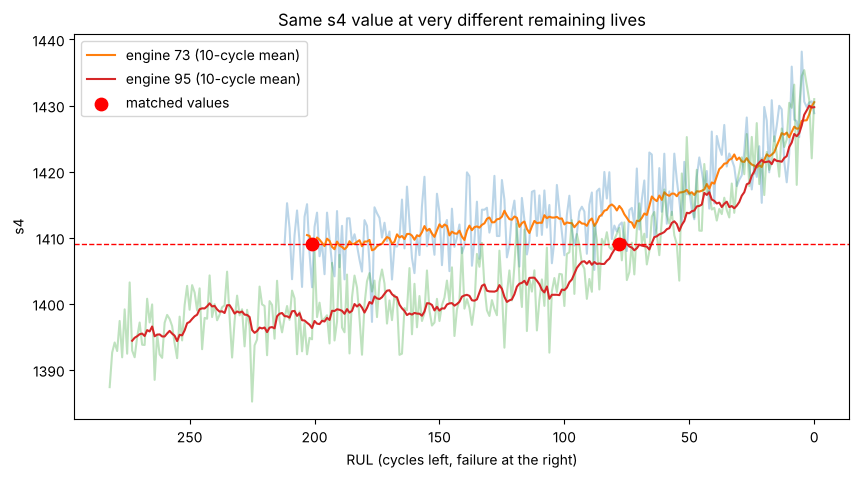

engine 73: s4=1409.00 at RUL=201
engine 95: s4=1409.00 at RUL=78
same reading (Δ=0.00), but RUL differs by 123 cycles


In [7]:
# Reuses q1_df (Q1, FD001 train).
q6_sensor = "s4"

q6_df = q1_df.copy()
q6_df["RUL"] = q6_df.groupby("unit")["cycle"].transform("max") - q6_df["cycle"]

smooth_list = []
for u in q6_df["unit"].unique():
    engine = q6_df[q6_df["unit"] == u]
    smooth_list.extend(engine[q6_sensor].rolling(10).mean().tolist())
q6_df["smooth"] = smooth_list

baseline = q6_df[q6_df["cycle"] <= 10].groupby("unit")[q6_sensor].mean()
q6_unit_a = baseline.idxmax()
q6_unit_b = baseline.idxmin()
print(f"highest starting baseline: engine {q6_unit_a} ({baseline[q6_unit_a]:.2f})")
print(f"lowest starting baseline: engine {q6_unit_b} ({baseline[q6_unit_b]:.2f})")
print("values below are 10-cycle rolling means, so single noisy readings do not drive the match")

engine_a = q6_df[(q6_df["unit"] == q6_unit_a) & (q6_df["cycle"] <= 20)].dropna()
engine_b = q6_df[q6_df["unit"] == q6_unit_b].dropna()

best_diff = None
for index_a, row_a in engine_a.iterrows():
    for index_b, row_b in engine_b.iterrows():
        diff = abs(row_a["smooth"] - row_b["smooth"])
        if best_diff is None or diff < best_diff:
            best_diff = diff
            q6_value_a = row_a["smooth"]
            q6_rul_a = int(row_a["RUL"])
            q6_value_b = row_b["smooth"]
            q6_rul_b = int(row_b["RUL"])

q6_rul_gap = q6_rul_a - q6_rul_b

plt.figure(figsize=(10, 5))
for u in [q6_unit_a, q6_unit_b]:
    engine = q6_df[q6_df["unit"] == u]
    plt.plot(engine["RUL"], engine[q6_sensor], alpha=0.3)
    plt.plot(engine["RUL"], engine["smooth"], label=f"engine {u} (10-cycle mean)")
plt.scatter([q6_rul_a, q6_rul_b], [q6_value_a, q6_value_b], color="red", s=80, zorder=5, label="matched values")
plt.axhline(q6_value_a, color="red", linestyle="--", linewidth=1)
plt.gca().invert_xaxis()
plt.xlabel("RUL (cycles left, failure at the right)")
plt.ylabel(q6_sensor)
plt.title(f"Same {q6_sensor} value at very different remaining lives")
plt.legend()
plt.show()
print(f"engine {q6_unit_a}: {q6_sensor}={q6_value_a:.2f} at RUL={q6_rul_a}")
print(f"engine {q6_unit_b}: {q6_sensor}={q6_value_b:.2f} at RUL={q6_rul_b}")
print(f"same reading (Δ={abs(q6_value_a - q6_value_b):.2f}), but RUL differs by {q6_rul_gap} cycles")

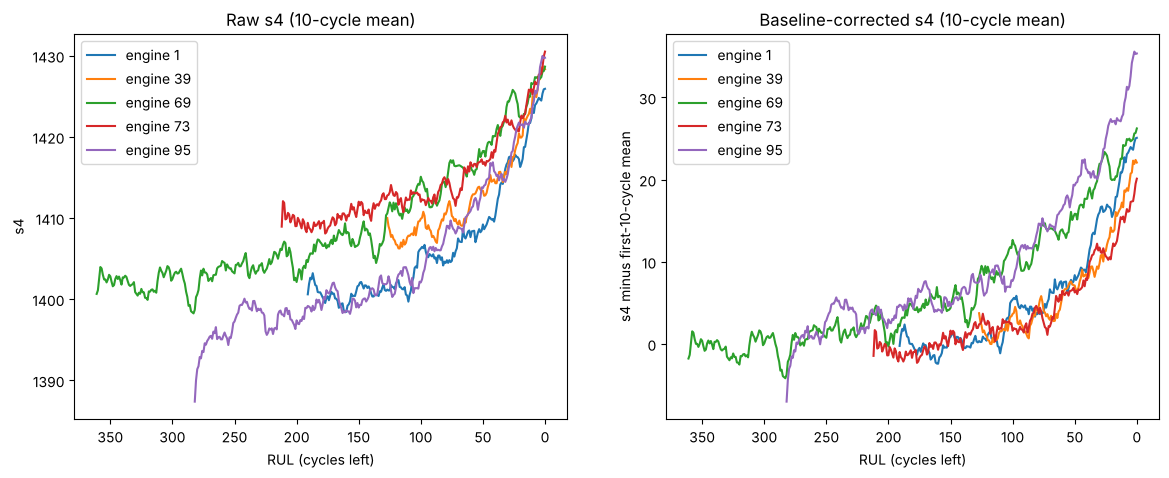

spread of the 10-cycle mean across engines
           point  n_engines  raw_spread_std  corrected_spread_std
cycle 10 (start)        100           4.483                 0.000
         RUL 150         93           4.500                 1.724
         RUL 100        100           4.544                 2.742
          RUL 50        100           4.085                 3.507
          RUL 20        100           3.082                 3.746
           RUL 0        100           1.439                 4.269


In [8]:
import matplotlib.pyplot as plt

# Reuses q1_df and q6_sensor. Per-engine baseline = mean of that engine's first few cycles.
baseline_cycles = 10

q6_corr_df = q1_df.copy()
q6_corr_df["RUL"] = q6_corr_df.groupby("unit")["cycle"].transform("max") - q6_corr_df["cycle"]
first_cycles = q6_corr_df[q6_corr_df["cycle"] <= baseline_cycles]
engine_baseline = first_cycles.groupby("unit")[q6_sensor].mean()
q6_corr_df["baseline"] = q6_corr_df["unit"].map(engine_baseline)
q6_corr_df["corrected"] = q6_corr_df[q6_sensor] - q6_corr_df["baseline"]

raw_smooth = []
corr_smooth = []
for u in q6_corr_df["unit"].unique():
    engine = q6_corr_df[q6_corr_df["unit"] == u]
    raw_smooth.extend(engine[q6_sensor].rolling(10, min_periods=1).mean().tolist())
    corr_smooth.extend(engine["corrected"].rolling(10, min_periods=1).mean().tolist())
q6_corr_df["raw_smooth"] = raw_smooth
q6_corr_df["corr_smooth"] = corr_smooth

plot_units = [1, 39, 69, q6_unit_a, q6_unit_b]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for u in plot_units:
    engine = q6_corr_df[q6_corr_df["unit"] == u]
    axes[0].plot(engine["RUL"], engine["raw_smooth"], label=f"engine {u}")
    axes[1].plot(engine["RUL"], engine["corr_smooth"], label=f"engine {u}")
axes[0].set_title(f"Raw {q6_sensor} (10-cycle mean)")
axes[1].set_title(f"Baseline-corrected {q6_sensor} (10-cycle mean)")
for ax in axes:
    ax.invert_xaxis()
    ax.set_xlabel("RUL (cycles left)")
    ax.legend()
axes[0].set_ylabel(q6_sensor)
axes[1].set_ylabel(f"{q6_sensor} minus first-{baseline_cycles}-cycle mean")
plt.show()

spread_rows = []
start_rows = q6_corr_df[q6_corr_df["cycle"] == baseline_cycles]
spread_rows.append({
    "point": f"cycle {baseline_cycles} (start)",
    "n_engines": len(start_rows),
    "raw_spread_std": round(start_rows["raw_smooth"].std(), 3),
    "corrected_spread_std": round(start_rows["corr_smooth"].std(), 3)
})
for rul_value in [150, 100, 50, 20, 0]:
    at_rul = q6_corr_df[q6_corr_df["RUL"] == rul_value]
    spread_rows.append({
        "point": f"RUL {rul_value}",
        "n_engines": len(at_rul),
        "raw_spread_std": round(at_rul["raw_smooth"].std(), 3),
        "corrected_spread_std": round(at_rul["corr_smooth"].std(), 3)
    })
print("spread of the 10-cycle mean across engines")
print(pd.DataFrame(spread_rows).to_string(index=False))

## 7. Operating regimes in FD002 (k-means)

In [9]:
import pandas as pd
from sklearn.cluster import KMeans

fd2 = pd.read_csv("data/CMAPSSData/train_FD002.txt", sep=r"\s+", header=None, names=q1_df.columns)
print("FD002 shape:", fd2.shape, "| engines:", fd2["unit"].nunique())

setting_cols = ["os1", "os2", "os3"]

inertia_rows = []
for k in range(2, 10):
    test_model = KMeans(n_clusters=k, n_init=10, random_state=0)
    test_model.fit(fd2[setting_cols])
    inertia_rows.append({"n_clusters": k, "inertia": round(test_model.inertia_, 2)})
print(pd.DataFrame(inertia_rows).to_string(index=False))

kmeans = KMeans(n_clusters=6, n_init=10, random_state=0)
fd2["op_cond"] = kmeans.fit_predict(fd2[setting_cols])
print(f"\nconditions recovered: {fd2['op_cond'].nunique()}")

cond_rows = []
for cond in sorted(fd2["op_cond"].unique()):
    group = fd2[fd2["op_cond"] == cond]
    cond_rows.append({
        "op_cond": cond,
        "rows": len(group),
        "os1_min": group["os1"].min(),
        "os1_max": group["os1"].max(),
        "os2_min": group["os2"].min(),
        "os2_max": group["os2"].max(),
        "os3": group["os3"].mean()
    })
print(pd.DataFrame(cond_rows).to_string(index=False))

q7_sensor = "s4"
q7_unit = 1

overall_std = fd2[q7_sensor].std()
cond_means = fd2.groupby("op_cond")[q7_sensor].mean()
between_spread = cond_means.max() - cond_means.min()
within_std = fd2.groupby("op_cond")[q7_sensor].std().mean()

engine = fd2[fd2["unit"] == q7_unit]
early = engine[engine["cycle"] <= 20]
late = engine[engine["cycle"] > engine["cycle"].max() - 20]
wear_rows = []
for cond in sorted(fd2["op_cond"].unique()):
    early_mean = early[early["op_cond"] == cond][q7_sensor].mean()
    late_mean = late[late["op_cond"] == cond][q7_sensor].mean()
    wear_rows.append({"op_cond": cond, "first_20_cycles": round(early_mean, 2), "last_20_cycles": round(late_mean, 2), "change": round(late_mean - early_mean, 2)})
wear_table = pd.DataFrame(wear_rows)

print(f"\nsensor {q7_sensor}, all FD002 rows")
print(f"overall std:                         {overall_std:.2f}")
print(f"spread between per-condition means:  {between_spread:.2f}")
print(f"average std within one condition:    {within_std:.2f}")
print(f"\nper-condition means of {q7_sensor}:")
print(cond_means.round(2).to_string())
print(f"\nengine {q7_unit} ({engine['cycle'].max()} cycles): early vs late {q7_sensor} inside each condition")
print(wear_table.to_string(index=False))

dead_rows = []
for col in q2_dead_cols:
    dead_rows.append({
        "column": col,
        "FD002_n_unique": fd2[col].nunique(),
        "FD002_std_overall": round(fd2[col].std(), 4),
        "max_std_within_condition": round(fd2.groupby("op_cond")[col].std().max(), 4)
    })
print("\nQ2 dead columns re-checked on FD002")
print(pd.DataFrame(dead_rows).to_string(index=False))

FD002 shape: (53759, 26) | engines: 260


 n_clusters     inertia
          2 11687220.03
          3  1865413.60
          4   650427.63
          5   246561.26
          6        0.41
          7        0.33
          8        0.27
          9        0.22

conditions recovered: 6
 op_cond  rows  os1_min  os1_max  os2_min  os2_max   os3
       0 13458   41.998   42.008     0.84    0.842 100.0
       1  8096    9.998   10.008     0.25    0.252 100.0
       2  8002   24.998   25.008     0.62    0.622  60.0
       3  8044    0.000    0.003     0.00    0.002 100.0
       4  8037   34.998   35.008     0.84    0.842 100.0
       5  8122   19.998   20.008     0.70    0.702 100.0

sensor s4, all FD002 rows
overall std:                         119.12
spread between per-condition means:  358.54
average std within one condition:    7.84

per-condition means of s4:
op_cond
0    1127.80
1    1311.25
2    1050.32
3    1408.86
4    1131.53
5    1253.12

engine 1 (149 cycles): early vs late s4 inside each condition
 op_cond  first_20_cycles 

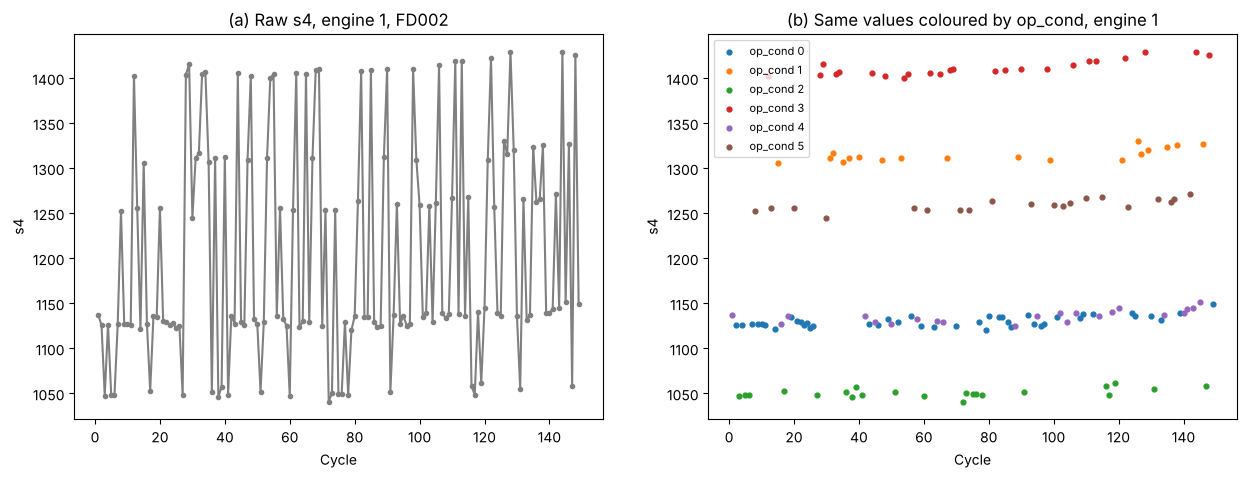

In [10]:
import matplotlib.pyplot as plt

# Reuses fd2, q7_sensor from the previous cell.
engine = fd2[fd2["unit"] == q7_unit]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(engine["cycle"], engine[q7_sensor], marker="o", markersize=3, color="grey")
axes[0].set_title(f"(a) Raw {q7_sensor}, engine {q7_unit}, FD002")
for cond in sorted(engine["op_cond"].unique()):
    cond_rows = engine[engine["op_cond"] == cond]
    axes[1].scatter(cond_rows["cycle"], cond_rows[q7_sensor], s=12, label=f"op_cond {cond}")
axes[1].set_title(f"(b) Same values coloured by op_cond, engine {q7_unit}")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("Cycle")
    ax.set_ylabel(q7_sensor)
plt.show()

## 8. Standardising sensors per operating condition

In [11]:
import numpy as np

sensor_cols = []
for i in range(1, 22):
    sensor_cols.append("s" + str(i))

fd2_norm = fd2.copy()
for col in sensor_cols:
    fd2_norm[col] = fd2_norm[col].astype(float)

guarded = []
for cond in sorted(fd2["op_cond"].unique()):
    mask = fd2["op_cond"] == cond
    for col in sensor_cols:
        mean_val = fd2.loc[mask, col].mean()
        std_val = fd2.loc[mask, col].std()
        if np.isnan(std_val) or std_val < 1e-8:
            fd2_norm.loc[mask, col] = 0.0
            guarded.append(f"cond {cond}: {col}")
        else:
            fd2_norm.loc[mask, col] = (fd2.loc[mask, col] - mean_val) / std_val

print(f"fd2 rows: {len(fd2)}, fd2_norm rows: {len(fd2_norm)}")
print(f"zero-variance (condition, sensor) groups set to 0 instead of dividing by zero: {len(guarded)}")
print(guarded)

q8_sensor = q7_sensor

fd2_rul = fd2.groupby("unit")["cycle"].transform("max") - fd2["cycle"]
engine_raw = fd2[fd2["unit"] == q7_unit]
engine_norm = fd2_norm[fd2_norm["unit"] == q7_unit]

before_means = fd2.groupby("op_cond")[q8_sensor].mean()
after_means = fd2_norm.groupby("op_cond")[q8_sensor].mean()

check_rows = []
check_rows.append({
    "statistic": "spread between per-condition means",
    "before": round(before_means.max() - before_means.min(), 3),
    "after": round(after_means.max() - after_means.min(), 3)
})
check_rows.append({
    "statistic": "overall std",
    "before": round(fd2[q8_sensor].std(), 3),
    "after": round(fd2_norm[q8_sensor].std(), 3)
})
check_rows.append({
    "statistic": f"corr with cycle, engine {q7_unit}",
    "before": round(engine_raw[q8_sensor].corr(engine_raw["cycle"]), 3),
    "after": round(engine_norm[q8_sensor].corr(engine_norm["cycle"]), 3)
})
check_rows.append({
    "statistic": "corr with RUL, all FD002 rows",
    "before": round(fd2[q8_sensor].corr(fd2_rul), 3),
    "after": round(fd2_norm[q8_sensor].corr(fd2_rul), 3)
})
print(f"\n{q8_sensor} before vs after per-condition standardisation")
print(pd.DataFrame(check_rows).to_string(index=False))

fd2 rows: 53759, fd2_norm rows: 53759
zero-variance (condition, sensor) groups set to 0 instead of dividing by zero: 30
['cond 0: s1', 'cond 0: s5', 'cond 0: s16', 'cond 0: s18', 'cond 0: s19', 'cond 1: s1', 'cond 1: s5', 'cond 1: s16', 'cond 1: s18', 'cond 1: s19', 'cond 2: s1', 'cond 2: s5', 'cond 2: s16', 'cond 2: s18', 'cond 2: s19', 'cond 3: s1', 'cond 3: s5', 'cond 3: s10', 'cond 3: s16', 'cond 3: s18', 'cond 3: s19', 'cond 4: s1', 'cond 4: s5', 'cond 4: s16', 'cond 4: s18', 'cond 4: s19', 'cond 5: s1', 'cond 5: s5', 'cond 5: s18', 'cond 5: s19']

s4 before vs after per-condition standardisation
                         statistic  before  after
spread between per-condition means 358.540  0.000
                       overall std 119.123  1.000
         corr with cycle, engine 1   0.135  0.679
     corr with RUL, all FD002 rows  -0.041 -0.662


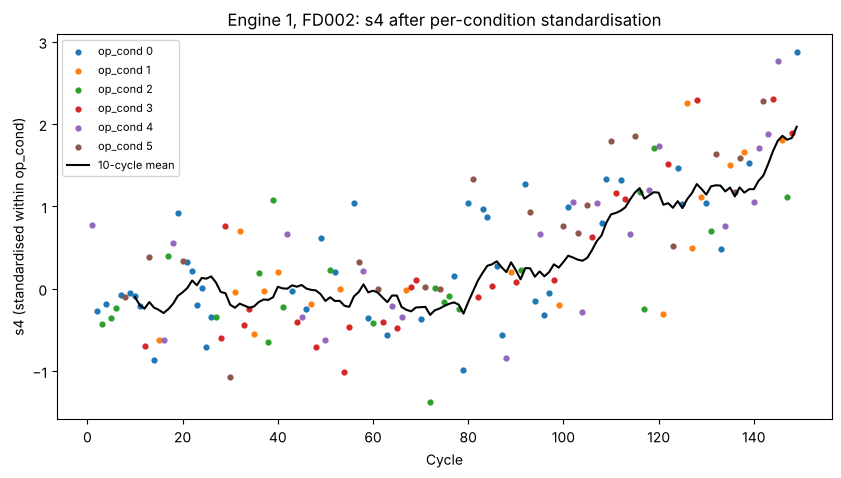

In [12]:
import matplotlib.pyplot as plt

# Reuses fd2, fd2_norm, q8_sensor from the previous cell; q7_unit comes from Q7.
engine_norm = fd2_norm[fd2_norm["unit"] == q7_unit]

plt.figure(figsize=(10, 5))
for cond in sorted(engine_norm["op_cond"].unique()):
    cond_rows = engine_norm[engine_norm["op_cond"] == cond]
    plt.scatter(cond_rows["cycle"], cond_rows[q8_sensor], s=12, label=f"op_cond {cond}")
plt.plot(engine_norm["cycle"], engine_norm[q8_sensor].rolling(10).mean(), color="black", label="10-cycle mean")
plt.xlabel("Cycle")
plt.ylabel(f"{q8_sensor} (standardised within op_cond)")
plt.title(f"Engine {q7_unit}, FD002: {q8_sensor} after per-condition standardisation")
plt.legend(fontsize=8)
plt.show()

## 9. Baseline-corrected sensor vs RUL

In [13]:
import pandas as pd

# Reuses q1_df (Q1, FD001 train) and the per-engine baseline idea from Q6.
q9_df = q1_df.copy()
q9_df["RUL"] = q9_df.groupby("unit")["cycle"].transform("max") - q9_df["cycle"]
q9_rul = q9_df["RUL"]

q9_sensor = "s4"
first_cycles = q9_df[q9_df["cycle"] <= 10]
engine_baseline = first_cycles.groupby("unit")[q9_sensor].mean()
q9_df["corrected"] = q9_df[q9_sensor] - q9_df["unit"].map(engine_baseline)
q9_corrected = q9_df["corrected"]

bin_labels = []
for r in q9_df["RUL"]:
    start = (r // 25) * 25
    if start >= 200:
        bin_labels.append("200+")
    else:
        bin_labels.append(f"{start:03d}-{start + 24:03d}")
q9_df["RUL_bin"] = bin_labels

bin_rows = []
for b in sorted(q9_df["RUL_bin"].unique()):
    group = q9_df[q9_df["RUL_bin"] == b]
    bin_rows.append({
        "RUL_bin": b,
        "rows": len(group),
        "mean_corrected": round(group["corrected"].mean(), 2),
        "std_corrected": round(group["corrected"].std(), 2)
    })
q9_bins = pd.DataFrame(bin_rows)
q9_bins = q9_bins.sort_values("RUL_bin", ascending=False).reset_index(drop=True)
q9_bins["change_vs_previous_bin"] = q9_bins["mean_corrected"].diff().round(2)
print(q9_bins.to_string(index=False))

q9_corr_all = q9_corrected.corr(q9_rul)
late = q9_df[q9_df["RUL"] < 100]
early = q9_df[q9_df["RUL"] >= 125]
print(f"\ncorrelation of corrected {q9_sensor} with RUL, all rows:  {q9_corr_all:.3f}")
print(f"correlation when RUL < 100:  {late['corrected'].corr(late['RUL']):.3f}")
print(f"correlation when RUL >= 125: {early['corrected'].corr(early['RUL']):.3f}")
print(f"correlation of raw {q9_sensor} with RUL, all rows:        {q9_df[q9_sensor].corr(q9_rul):.3f}")

RUL_bin  rows  mean_corrected  std_corrected  change_vs_previous_bin
   200+  2004            0.50           4.09                     NaN
175-199  1608            0.80           4.18                    0.30
150-174  2088            1.17           4.26                    0.37
125-149  2431            1.72           4.47                    0.55
100-124  2500            3.09           4.69                    1.37
075-099  2500            4.94           4.81                    1.85
050-074  2500            7.88           5.14                    2.94
025-049  2500           12.99           5.53                    5.11
000-024  2500           21.28           6.49                    8.29

correlation of corrected s4 with RUL, all rows:  -0.690
correlation when RUL < 100:  -0.756
correlation when RUL >= 125: -0.106
correlation of raw s4 with RUL, all rows:        -0.679


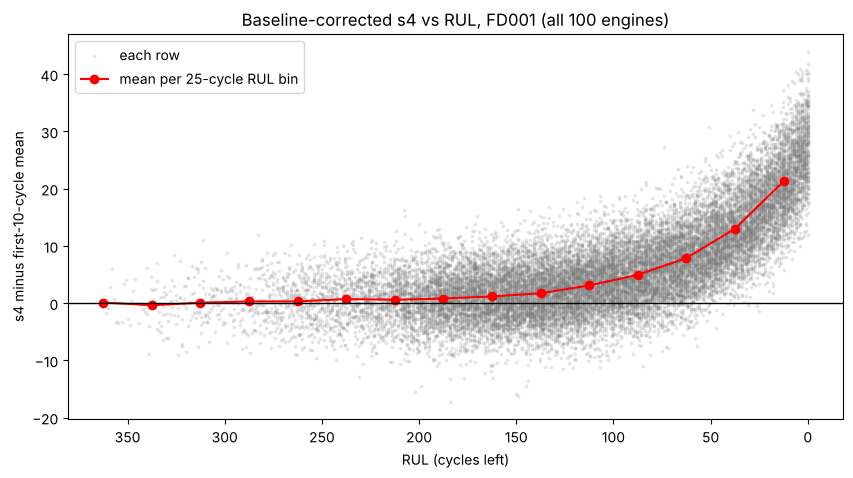

In [14]:
import matplotlib.pyplot as plt

# Reuses q9_rul, q9_sensor, q9_corrected from the previous cell.
bin_mid = []
bin_mean = []
for start in range(0, 375, 25):
    in_bin = q9_corrected[(q9_rul >= start) & (q9_rul < start + 25)]
    if len(in_bin) > 0:
        bin_mid.append(start + 12.5)
        bin_mean.append(in_bin.mean())

plt.figure(figsize=(10, 5))
plt.scatter(q9_rul, q9_corrected, s=3, alpha=0.15, color="grey", label="each row")
plt.plot(bin_mid, bin_mean, color="red", marker="o", label="mean per 25-cycle RUL bin")
plt.axhline(0, color="black", linewidth=1)
plt.gca().invert_xaxis()
plt.xlabel("RUL (cycles left)")
plt.ylabel(f"{q9_sensor} minus first-10-cycle mean")
plt.title(f"Baseline-corrected {q9_sensor} vs RUL, FD001 (all 100 engines)")
plt.legend()
plt.show()

## 10. Health states and a hard warning threshold

In [15]:
import numpy as np
import pandas as pd

# Reuses RUL target and baseline-corrected sensor from Q9.
q10_df = q9_df.copy()

critical_cut = 25
warning_cut = 125

state_list = []
for r in q10_df["RUL"]:
    if r <= critical_cut:
        state_list.append("critical")
    elif r <= warning_cut:
        state_list.append("warning")
    else:
        state_list.append("healthy")
q10_df["state"] = state_list

print("RUL distribution (all FD001 rows)")
print(q10_df["RUL"].describe().round(1).to_string())
print(f"\nshortest engine life: {q1_life_min} cycles, so every engine has rows from RUL 0 to RUL {q1_life_min - 1}")

state_order = ["healthy", "warning", "critical"]
state_rows = []
for s in state_order:
    group = q10_df[q10_df["state"] == s]
    state_rows.append({
        "state": s,
        "rows": len(group),
        "share_%": round(len(group) / len(q10_df) * 100, 1),
        "engines": group["unit"].nunique(),
        "mean": round(group["corrected"].mean(), 2),
        "std": round(group["corrected"].std(), 2),
        "p10": round(group["corrected"].quantile(0.10), 2),
        "p90": round(group["corrected"].quantile(0.90), 2)
    })
q10_states = pd.DataFrame(state_rows)
print(f"\nbaseline-corrected {q9_sensor} by health state")
print(q10_states.to_string(index=False))

q10_threshold = q10_states[q10_states["state"] == "critical"]["p10"].iloc[0]
healthy_rows = q10_df[q10_df["state"] == "healthy"]
warning_rows = q10_df[q10_df["state"] == "warning"]
critical_rows = q10_df[q10_df["state"] == "critical"]
healthy_above = (healthy_rows["corrected"] > q10_threshold).mean() * 100
warning_above = (warning_rows["corrected"] > q10_threshold).mean() * 100
critical_below = (critical_rows["corrected"] <= q10_threshold).mean() * 100
print(f"\nhard threshold X = {q10_threshold:.2f} (10th percentile of the critical state)")
print(f"healthy rows above X:  {healthy_above:.1f}%")
print(f"warning rows above X:  {warning_above:.1f}%")
print(f"critical rows below X: {critical_below:.1f}%")

first_cross = []
for u in q10_df["unit"].unique():
    engine = q10_df[q10_df["unit"] == u]
    crossed = engine[engine["corrected"] > q10_threshold]
    if len(crossed) > 0:
        first_cross.append(crossed["RUL"].iloc[0])
first_cross = pd.Series(first_cross)
print(f"\nRUL at the first cycle each engine crosses X ({len(first_cross)} engines):")
print(f"min {first_cross.min()}, median {first_cross.median()}, max {first_cross.max()}")
print(f"engines that cross X with more than {critical_cut} cycles left: {(first_cross > critical_cut).sum()}")

RUL distribution (all FD001 rows)
count    20631.0
mean       107.8
std         68.9
min          0.0
25%         51.0
50%        103.0
75%        155.0
max        361.0

shortest engine life: 128 cycles, so every engine has rows from RUL 0 to RUL 127

baseline-corrected s4 by health state
   state  rows  share_%  engines  mean  std   p10   p90
 healthy  8031     38.9      100  1.07 4.29 -4.29  6.58
 warning 10000     48.5      100  7.10 6.23 -0.46 15.29
critical  2600     12.6      100 21.06 6.54 12.74 29.74

hard threshold X = 12.74 (10th percentile of the critical state)
healthy rows above X:  0.5%
warning rows above X:  17.9%
critical rows below X: 10.0%

RUL at the first cycle each engine crosses X (100 engines):
min 29, median 84.0, max 208
engines that cross X with more than 25 cycles left: 100


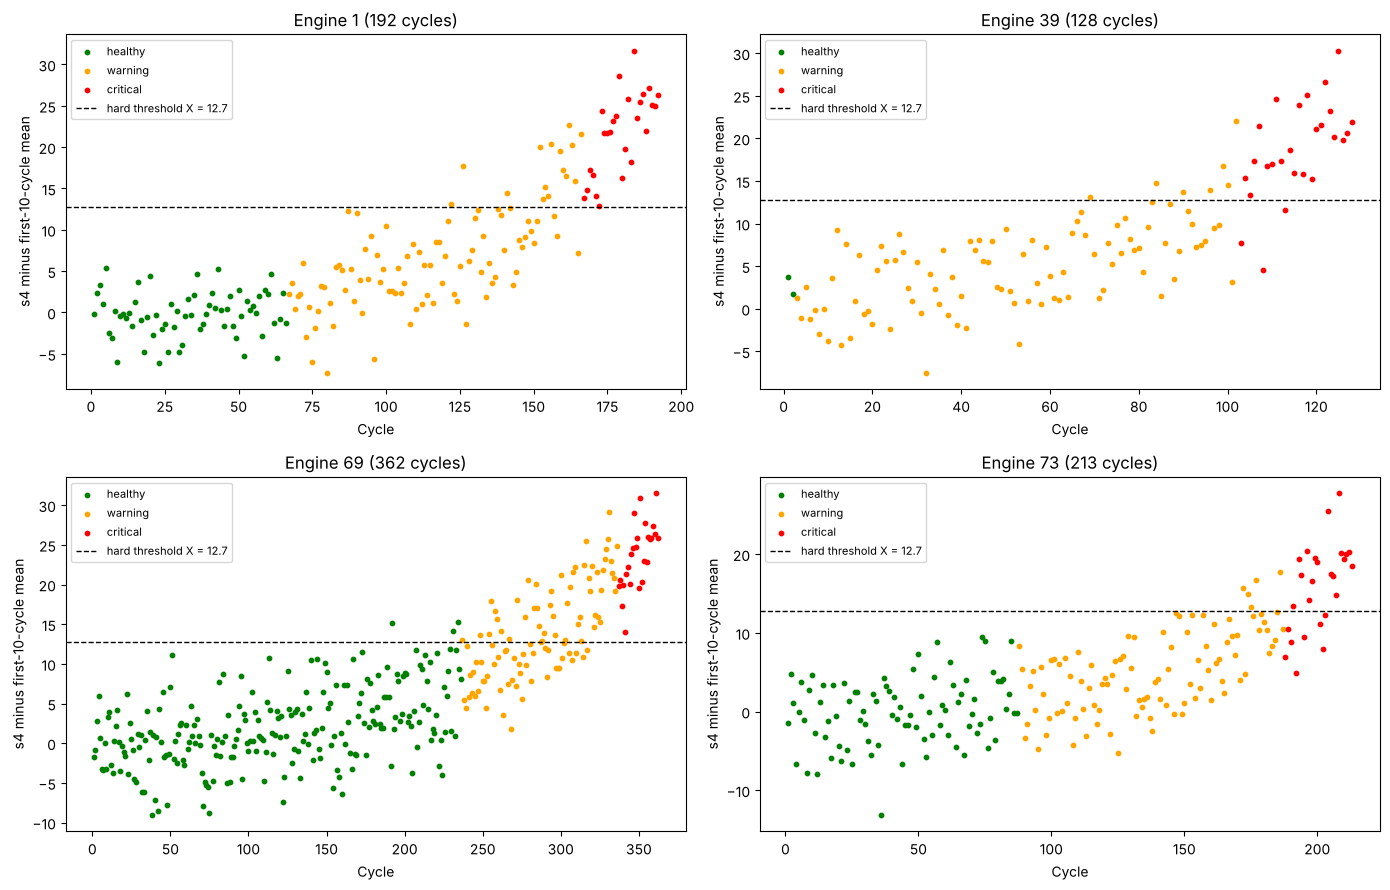

In [16]:
import matplotlib.pyplot as plt

q10_units = [1, 39, 69, 73]
state_colours = {"healthy": "green", "warning": "orange", "critical": "red"}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()
for i in range(len(q10_units)):
    u = q10_units[i]
    engine = q10_df[q10_df["unit"] == u]
    for s in state_order:
        state_rows = engine[engine["state"] == s]
        axes[i].scatter(state_rows["cycle"], state_rows["corrected"], s=10, color=state_colours[s], label=s)
    axes[i].axhline(q10_threshold, color="black", linestyle="--", linewidth=1, label=f"hard threshold X = {q10_threshold:.1f}")
    axes[i].set_title(f"Engine {u} ({engine['cycle'].max()} cycles)")
    axes[i].set_xlabel("Cycle")
    axes[i].set_ylabel(f"{q9_sensor} minus first-10-cycle mean")
    axes[i].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 11. Join the test set with its true RUL

In [17]:
import pandas as pd

test = pd.read_csv("data/CMAPSSData/test_FD001.txt", sep=r"\s+", header=None, names=q1_df.columns)
rul_file = pd.read_csv("data/CMAPSSData/RUL_FD001.txt", sep=r"\s+", header=None, names=["true_rul"])
print("test shape:", test.shape, "| RUL file shape:", rul_file.shape)

q11_last = test.groupby("unit").tail(1)
q11_last = q11_last.sort_values("unit").reset_index(drop=True)

units = q11_last["unit"].tolist()
expected_units = list(range(1, len(rul_file) + 1))
print(f"check 1: number of test engines = {len(q11_last)}, number of RUL values = {len(rul_file)}, match = {len(q11_last) == len(rul_file)}")
print(f"check 2: test engine ids are exactly 1 to {len(rul_file)} with no gaps = {units == expected_units}")

in_order = True
for u in test["unit"].unique():
    engine_cycles = test[test["unit"] == u]["cycle"].tolist()
    if engine_cycles != list(range(1, len(engine_cycles) + 1)):
        in_order = False
print(f"check 3: every test engine's cycles run 1, 2, 3, ... with no gaps = {in_order}")

q11_last["true_rul"] = rul_file["true_rul"].values
q11_last["total_life"] = q11_last["cycle"] + q11_last["true_rul"]
print(f"check 4: implied total life of test engines = {q11_last['total_life'].min()} to {q11_last['total_life'].max()} cycles, train lifetimes = {q1_life_min} to {q1_life_max} cycles")

aligned_corr = q11_last["s4"].corr(q11_last["true_rul"])
shifted_rul = list(rul_file["true_rul"].values[1:]) + [rul_file["true_rul"].values[0]]
shifted_corr = q11_last["s4"].corr(pd.Series(shifted_rul))
print(f"check 5: corr of last-cycle s4 with true RUL, aligned = {aligned_corr:.3f}, if shifted by one engine = {shifted_corr:.3f}")

q11_assert_ok = len(q11_last) == len(rul_file) and units == expected_units and in_order
assert q11_assert_ok, "join may be misaligned"

print(f"\ntrue remaining life: min = {q11_last['true_rul'].min()}, max = {q11_last['true_rul'].max()}")
print(q11_last[["unit", "cycle", "true_rul", "total_life"]].head().to_string(index=False))

test shape: (13096, 26) | RUL file shape: (100, 1)
check 1: number of test engines = 100, number of RUL values = 100, match = True
check 2: test engine ids are exactly 1 to 100 with no gaps = True
check 3: every test engine's cycles run 1, 2, 3, ... with no gaps = True
check 4: implied total life of test engines = 141 to 341 cycles, train lifetimes = 128 to 362 cycles
check 5: corr of last-cycle s4 with true RUL, aligned = -0.761, if shifted by one engine = -0.060

true remaining life: min = 7, max = 145
 unit  cycle  true_rul  total_life
    1     31       112         143
    2     49        98         147
    3    126        69         195
    4    106        82         188
    5     98        91         189


**Interpretation**

**State the join assumption, the sanity check, and the min/max true RUL.** Provide your answer in this cell.
**Assumption.** Since RUL_FD001.txt has no engine id, the join relies on position: line i of the RUL file belongs to test engine i, so both files list the engines in the same order, 1 to 100. I sorted the last-cycle table by unit and attached the RUL values in file order.

**Sanity checks.** (1) Both sides have exactly 100 entries. (2) The test engine ids run exactly from 1 to 100 with no gaps, so there is no missing engine that could shift everything by one. (3) Every test engine's cycles run 1, 2, 3 and so on without gaps, so the last row really is the last observed cycle. (4) The implied total life (last cycle plus true RUL) ranges from 141 to 341 cycles, which sits inside the training range of 128 to 362 cycles, so no engine ends up with an impossible lifetime. (5) The strongest check is physical: at the last cycle, s4 has a correlation of -0.761 with the attached true RUL, meaning hotter (more worn) engines have less life left, as expected. If the RUL values are shifted by just one engine, this correlation collapses to -0.060. A silent misalignment would destroy the relationship, so the fact that it is strong shows the alignment is correct.

**Result.** The true remaining life ranges from a minimum of 7 cycles to a maximum of 145 cycles.

## 12. Linear Regression vs Random Forest

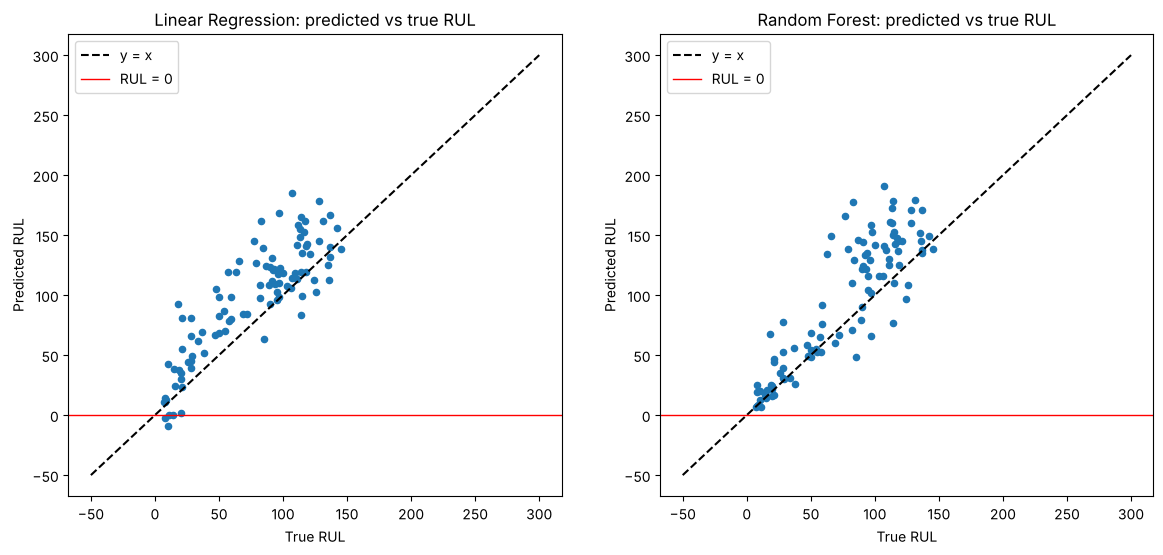

                                         0              1
model                    Linear Regression  Random Forest
RMSE                                 31.95          32.93
mean_residual                        21.16          19.44
negative_preds                           3              0
min_pred                              -9.1            6.6
max_pred                             185.4          191.3
mean_resid_true_0-25                  11.7            7.7
mean_resid_true_25-50                 28.0           10.5
mean_resid_true_50-100                29.8           25.4
mean_resid_true_100-150               15.1           22.7

test engines per true-RUL bin: 0-25: 19, 25-50: 11, 50-100: 36, 100-150: 34



dead sensors inside the two models
sensor  LR_coefficient  LR_coef_x_train_std  RF_importance
    s1          0.0000               0.0000         0.0000
    s5         -0.0000              -0.0000         0.0000
    s6       -507.0392              -0.7043         0.0008
   s10         -0.0000              -0.0000         0.0000
   s16          0.0000               0.0000         0.0000
   s18         -0.0000              -0.0000         0.0000
   s19          0.0000               0.0000         0.0000
total RF importance on dead sensors: 0.00080


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Provided model code (given - internals not required). Reuses q1_df (Q1, FD001 train)
# and q11_last (Q11, each test engine's last cycle with its true RUL attached).
q12_feat = [f"s{i}" for i in range(1, 22)]          # still includes the dead sensors from Q2
train = q1_df.copy()
train["RUL"] = train.groupby("unit").cycle.transform("max") - train["cycle"]
last = q11_last

lr = LinearRegression().fit(train[q12_feat], train["RUL"])
rf = RandomForestRegressor(n_estimators=100, random_state=0).fit(train[q12_feat], train["RUL"])
q12_pred_lr = lr.predict(last[q12_feat])
q12_pred_rf = rf.predict(last[q12_feat])
q12_true = last["true_rul"].to_numpy()

models = {"Linear Regression": q12_pred_lr, "Random Forest": q12_pred_rf}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
i = 0
for name in models:
    pred = models[name]
    axes[i].scatter(q12_true, pred, s=20)
    axes[i].plot([-50, 300], [-50, 300], color="black", linestyle="--", label="y = x")
    axes[i].axhline(0, color="red", linewidth=1, label="RUL = 0")
    axes[i].set_xlabel("True RUL")
    axes[i].set_ylabel("Predicted RUL")
    axes[i].set_title(f"{name}: predicted vs true RUL")
    axes[i].legend()
    i = i + 1
plt.show()

bins = [(0, 25), (25, 50), (50, 100), (100, 150)]
summary_rows = []
for name in models:
    pred = models[name]
    residual = pred - q12_true
    row = {
        "model": name,
        "RMSE": round(np.sqrt(np.mean(residual ** 2)), 2),
        "mean_residual": round(residual.mean(), 2),
        "negative_preds": int((pred < 0).sum()),
        "min_pred": round(pred.min(), 1),
        "max_pred": round(pred.max(), 1)
    }
    for low, high in bins:
        in_bin = (q12_true >= low) & (q12_true < high)
        row[f"mean_resid_true_{low}-{high}"] = round(residual[in_bin].mean(), 1)
    summary_rows.append(row)
q12_summary = pd.DataFrame(summary_rows)
print(q12_summary.T.to_string())

engines_per_bin = []
for low, high in bins:
    engines_per_bin.append(f"{low}-{high}: {int(((q12_true >= low) & (q12_true < high)).sum())}")
print("\ntest engines per true-RUL bin:", ", ".join(engines_per_bin))

dead_rows = []
for col in q2_dead_cols:
    if col in q12_feat:
        idx = q12_feat.index(col)
        dead_rows.append({
            "sensor": col,
            "LR_coefficient": round(lr.coef_[idx], 4),
            "LR_coef_x_train_std": round(lr.coef_[idx] * train[col].std(), 4),
            "RF_importance": round(rf.feature_importances_[idx], 5)
        })
print("\ndead sensors inside the two models")
print(pd.DataFrame(dead_rows).to_string(index=False))
print(f"total RF importance on dead sensors: {pd.DataFrame(dead_rows)['RF_importance'].sum():.5f}")

**Interpretation**

**Which model is more trustworthy for end-of-life prediction, argued from the residual pattern - and do the dead sensors hurt either model?** Provide your answer in this cell.
On a single summary number the two models look almost the same (RMSE 31.95 for Linear Regression and 32.93 for Random Forest), so the choice has to come from the residual pattern. Both models are biased upwards overall (mean residual +21.16 and +19.44), meaning they tend to claim more life than is left, and both are worst in the 50 to 100 range (mean residual +29.8 for LR and +25.4 for RF). The difference shows near end-of-life. Linear Regression predicts a negative RUL for 3 engines (as low as -9.1), which is physically impossible, while Random Forest never goes below 6.6. For the 19 engines with true RUL under 25, RF's mean residual is +7.7 against +11.7 for LR, and for true RUL 25 to 50 the gap is even bigger (+10.5 against +28.0). In the scatter, RF's points hug the y = x line below a true RUL of about 50, whereas LR's points fan out both above and below it, with some engines that have about 20 cycles left predicted at around 80 to 90. RF is worse for engines far from failure (+22.7 against +15.1 above RUL 100), but errors there matter less because there is still plenty of time to correct the plan. So I would trust Random Forest more for end-of-life prediction, because its errors are smallest and physically sensible exactly where a wrong answer is most costly. Its predictions also stop at about 191 while true values in the test set only reach 145, so neither model should be trusted for very long horizons.

The dead sensors do not appear to hurt either model. In the Random Forest their combined importance is only 0.0008, so the trees almost never split on them, since a constant column cannot be split. In the Linear Regression the truly constant columns get a coefficient of 0. s6 gets a large-looking coefficient of -507, but because s6 only flips between 21.60 and 21.61, its actual effect is about -0.70 cycles per standard deviation, which is negligible. They add nothing, but they do no visible harm in FD001.

## 13. Where the Random Forest goes wrong

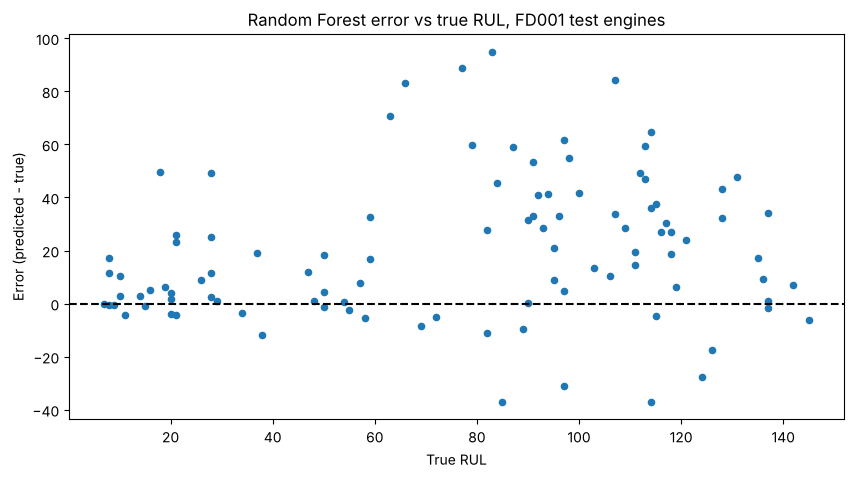

true_RUL  engines  mean_error  mean_abs_error  optimistic_engines
    0-25       19         7.7             9.2                  13
   25-50       11        10.5            13.2                   9
   50-75       13        16.3            19.8                   8
  75-100       23        30.5            38.2                  19
 100-150       34        22.7            28.2                  28

engines with true RUL < 25: 19, of which predicted to have 10+ more cycles than they really do: 6
largest optimistic error among them: 49.4 cycles


In [19]:
import numpy as np
import matplotlib.pyplot as plt

q13_error = q12_pred_rf - q12_true

plt.figure(figsize=(10, 5))
plt.scatter(q12_true, q13_error, s=20)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("True RUL")
plt.ylabel("Error (predicted - true)")
plt.title("Random Forest error vs true RUL, FD001 test engines")
plt.show()

error_rows = []
for low, high in [(0, 25), (25, 50), (50, 75), (75, 100), (100, 150)]:
    in_bin = (q12_true >= low) & (q12_true < high)
    error_rows.append({
        "true_RUL": f"{low}-{high}",
        "engines": int(in_bin.sum()),
        "mean_error": round(q13_error[in_bin].mean(), 1),
        "mean_abs_error": round(np.abs(q13_error[in_bin]).mean(), 1),
        "optimistic_engines": int((q13_error[in_bin] > 0).sum())
    })
print(pd.DataFrame(error_rows).to_string(index=False))

low_rul = q12_true < 25
print(f"\nengines with true RUL < 25: {int(low_rul.sum())}, of which predicted to have 10+ more cycles than they really do: {int((q13_error[low_rul] >= 10).sum())}")
print(f"largest optimistic error among them: {q13_error[low_rul].max():.1f} cycles")

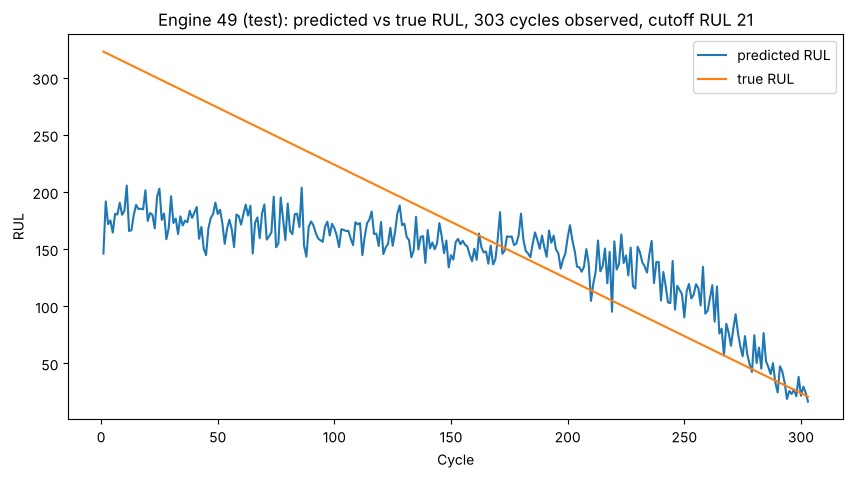

        part  cycles true_RUL_range  pred_mean  pred_min  pred_max  mean_error  mean_abs_error
 first third   1-101        323-223      174.1     143.5     205.8       -98.9            98.9
middle third 102-202        222-122      157.0     133.1     188.3       -15.0            26.8
  last third 203-303         121-21       96.9      16.6     163.0        25.9            27.1

error at first cycle: -176.8, error at last cycle: -4.4


highest RUL the forest predicts anywhere on the training set: 295.2, longest true RUL in training: 361


In [20]:
import numpy as np
import matplotlib.pyplot as plt

u = test[test.unit == 49].sort_values("cycle")
cutoff = q11_last.loc[q11_last.unit == 49, "true_rul"].iloc[0]
true_rul = cutoff + (u.cycle.max() - u.cycle)
pred_rul = rf.predict(u[q12_feat])

plt.figure(figsize=(10, 5))
plt.plot(u.cycle, pred_rul, label="predicted RUL")
plt.plot(u.cycle, true_rul, label="true RUL")
plt.xlabel("Cycle")
plt.ylabel("RUL")
plt.title(f"Engine 49 (test): predicted vs true RUL, {u.cycle.max()} cycles observed, cutoff RUL {cutoff}")
plt.legend()
plt.show()

error_49 = pred_rul - true_rul.to_numpy()
n_cycles = len(u)
third = n_cycles // 3
part_rows = []
part_names = ["first third", "middle third", "last third"]
part_starts = [0, third, 2 * third]
part_ends = [third, 2 * third, n_cycles]
for k in range(3):
    start = part_starts[k]
    end = part_ends[k]
    part_rows.append({
        "part": part_names[k],
        "cycles": f"{u.cycle.iloc[start]}-{u.cycle.iloc[end - 1]}",
        "true_RUL_range": f"{true_rul.iloc[start]}-{true_rul.iloc[end - 1]}",
        "pred_mean": round(pred_rul[start:end].mean(), 1),
        "pred_min": round(pred_rul[start:end].min(), 1),
        "pred_max": round(pred_rul[start:end].max(), 1),
        "mean_error": round(error_49[start:end].mean(), 1),
        "mean_abs_error": round(np.abs(error_49[start:end]).mean(), 1)
    })
print(pd.DataFrame(part_rows).to_string(index=False))
print(f"\nerror at first cycle: {error_49[0]:.1f}, error at last cycle: {error_49[-1]:.1f}")
print(f"highest RUL the forest predicts anywhere on the training set: {rf.predict(train[q12_feat]).max():.1f}, longest true RUL in training: {train['RUL'].max()}")

## 14. Do baseline-corrected features help?

In [21]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

def baseline_correct(data, sensors, n_cycles=10):
    corrected = data.copy()
    for u in data["unit"].unique():
        engine_mask = data["unit"] == u
        first_rows = data[engine_mask & (data["cycle"] <= n_cycles)]
        for col in sensors:
            corrected.loc[engine_mask, col] = data.loc[engine_mask, col] - first_rows[col].mean()
    return corrected

train_raw = q1_df.copy()
for col in q12_feat:
    train_raw[col] = train_raw[col].astype(float)
train_corr = baseline_correct(train_raw, q12_feat)
train_corr["RUL"] = train_corr.groupby("unit")["cycle"].transform("max") - train_corr["cycle"]

test_raw = test.copy()
for col in q12_feat:
    test_raw[col] = test_raw[col].astype(float)
test_corr = baseline_correct(test_raw, q12_feat)
last_corr = test_corr.groupby("unit").tail(1).sort_values("unit").reset_index(drop=True)

print(f"shortest test engine: {test.groupby('unit')['cycle'].max().min()} cycles, so every test engine has 10 cycles for its baseline")
print(f"test last rows line up with Q11: {(last_corr['unit'].to_numpy() == q11_last['unit'].to_numpy()).all()}")

lr_corr = LinearRegression().fit(train_corr[q12_feat], train_corr["RUL"])
rf_corr = RandomForestRegressor(n_estimators=100, random_state=0).fit(train_corr[q12_feat], train_corr["RUL"])
q14_pred_lr = lr_corr.predict(last_corr[q12_feat])
q14_pred_rf = rf_corr.predict(last_corr[q12_feat])

q14_results = {
    ("Linear Regression", "raw"): q12_pred_lr,
    ("Linear Regression", "corrected"): q14_pred_lr,
    ("Random Forest", "raw"): q12_pred_rf,
    ("Random Forest", "corrected"): q14_pred_rf
}

bins = [(0, 25), (25, 50), (50, 100), (100, 150)]
result_rows = []
for key in q14_results:
    pred = q14_results[key]
    residual = pred - q12_true
    row = {
        "model": key[0],
        "features": key[1],
        "RMSE": round(np.sqrt(np.mean(residual ** 2)), 2),
        "corr": round(np.corrcoef(pred, q12_true)[0, 1], 3),
        "mean_residual": round(residual.mean(), 2),
        "negative_preds": int((pred < 0).sum())
    }
    for low, high in bins:
        in_bin = (q12_true >= low) & (q12_true < high)
        row[f"abs_err_{low}-{high}"] = round(np.abs(residual[in_bin]).mean(), 1)
    result_rows.append(row)
q14_table = pd.DataFrame(result_rows)
print(q14_table.to_string(index=False))

shortest test engine: 31 cycles, so every test engine has 10 cycles for its baseline
test last rows line up with Q11: True


            model  features  RMSE  corr  mean_residual  negative_preds  abs_err_0-25  abs_err_25-50  abs_err_50-100  abs_err_100-150
Linear Regression       raw 31.95 0.861          21.16               3          19.3           28.0            31.0             22.4
Linear Regression corrected 29.33 0.885          15.70               9          27.9           22.8            28.2             19.0
    Random Forest       raw 32.93 0.875          19.44               0           9.2           13.2            31.5             28.2
    Random Forest corrected 26.61 0.883           9.57               0           7.9            9.5            18.2             29.7


## 15. The asymmetric scoring function

In [22]:
import numpy as np

# Provided metric (given). Constants as set in the question.
def cost(pred, true, a1=13, a2=10):
    d = np.asarray(pred) - np.asarray(true)
    return np.where(d < 0, np.exp(-d / a1) - 1, np.exp(d / a2) - 1).sum()

cost_rows = []
for d in [-50, -30, -20, -10, -5, 0, 5, 10, 20, 30, 50]:
    if d < 0:
        direction = "under-estimate (early)"
    elif d > 0:
        direction = "over-estimate (late)"
    else:
        direction = "perfect"
    cost_rows.append({
        "d (pred - true)": d,
        "direction": direction,
        "cost": round(cost([d], [0]), 2),
        "abs_error": abs(d),
        "squared_error": d ** 2
    })
print(pd.DataFrame(cost_rows).to_string(index=False))

print()
for d in [10, 20, 30, 50]:
    late_cost = cost([d], [0])
    early_cost = cost([-d], [0])
    print(f"|d| = {d}: late costs {late_cost:.2f}, early costs {early_cost:.2f}, late is {late_cost / early_cost:.1f}x worse")

print()
one_big = cost([50], [0])
five_small = cost([10, 10, 10, 10, 10], [0, 0, 0, 0, 0])
print(f"one engine 50 cycles late: cost {one_big:.2f}")
print(f"five engines 10 cycles late each (same total error of 50): cost {five_small:.2f}")

print()
rf_total = cost(q12_pred_rf, q12_true)
print(f"total cost on FD001 test, Linear Regression raw: {cost(q12_pred_lr, q12_true):.1f}")
print(f"total cost on FD001 test, Random Forest raw:     {rf_total:.1f}")

engine_rows = []
for k in range(len(q12_true)):
    engine_rows.append({
        "unit": int(q11_last["unit"].iloc[k]),
        "true_rul": q12_true[k],
        "rf_pred": round(q12_pred_rf[k], 1),
        "d": round(q12_pred_rf[k] - q12_true[k], 1),
        "cost": round(cost([q12_pred_rf[k]], [q12_true[k]]), 1)
    })
engine_costs = pd.DataFrame(engine_rows).sort_values("cost", ascending=False)
top5 = engine_costs.head(5)
print("\nRandom Forest engines with the largest cost")
print(top5.to_string(index=False))
print(f"share of the RF total cost from these 5 engines: {top5['cost'].sum() / rf_total * 100:.1f}%")

 d (pred - true)              direction   cost  abs_error  squared_error
             -50 under-estimate (early)  45.81         50           2500
             -30 under-estimate (early)   9.05         30            900
             -20 under-estimate (early)   3.66         20            400
             -10 under-estimate (early)   1.16         10            100
              -5 under-estimate (early)   0.47          5             25
               0                perfect   0.00          0              0
               5   over-estimate (late)   0.65          5             25
              10   over-estimate (late)   1.72         10            100
              20   over-estimate (late)   6.39         20            400
              30   over-estimate (late)  19.09         30            900
              50   over-estimate (late) 147.41         50           2500

|d| = 10: late costs 1.72, early costs 1.16, late is 1.5x worse
|d| = 20: late costs 6.39, early costs 3.66, late is 1.7x w

**Interpretation**

**What this cost function intends, and why.** Provide your answer in this cell.
**(a) Why exponential.** With an exponential penalty, each extra step of error multiplies the cost instead of adding to it. For late predictions, the cost goes from 1.72 at 10 cycles to 6.39 at 20, 19.09 at 30 and 147.41 at 50. Between 10 and 50 cycles the absolute error grows 5 times and the squared error 25 times, but this cost grows about 86 times. The table also shows that one engine predicted 50 cycles late costs 147.41, whereas five engines each 10 cycles late (the same total error of 50) cost only 8.59 in total. So the function is meant to discourage occasional large misses much more than many small ones. It rewards a model that is consistently close, because a single badly wrong prediction is what leads to an engine failing in service or being grounded with no warning. The FD001 results show this clearly. Random Forest's total cost (34,631.6) is far higher than Linear Regression's (13,050.9) even though their RMSEs were almost the same in Q12, because five RF engines were predicted between 70.9 and 95.0 cycles too late (for example, engine 15 with a true RUL of 83 was predicted at 178.0), and those five engines alone make up 87.8% of RF's total cost.

**(b) Which direction is discouraged more.** Since a2 = 10 is smaller than a1 = 13, a positive d (over-estimating the remaining life, so predicting failure too late) grows faster than a negative d (under-estimating, so predicting too early). At 10 cycles off, late costs 1.72 against 1.16 for early (1.5 times worse), and the gap widens with size, reaching 147.41 against 45.81 at 50 cycles (3.2 times worse). This is the right choice for maintenance. A late prediction means the engine is kept in service longer than it can actually last, which risks an in-flight failure, safety consequences and a much more expensive unplanned repair. An early prediction only means maintenance happens sooner than needed, which wastes some useful life and money but keeps the aircraft safe.